# Owner: SONG Haoyu, M4b implementation; shared M4 with FOTSING TANKOU DAN KATEL
# CatBoost, model errors and risk factors

Our question is simple: can a model built for categorical data improve on the course models, and what is it using to make predictions? We keep all tuning and interpretation in the training years. The final notebook handles the test years once all model choices are fixed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.config import RANDOM_STATE, RESULTS_DIR, FIGURES_DIR
from src.models.m4_common import (CACHE, environment, fingerprint, load_training,
    grouped_folds, oof_predict, score_oof, tune_candidates)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RUN_ID = fingerprint()
print('Run:', RUN_ID)
print(environment())
X, y, groups, meta = load_training()
print(f'{len(X):,} training people; {groups.nunique():,} accidents; KSI rate {y.mean():.2%}')
folds = grouped_folds(X, y, groups, 'full_train')
print('Five accident-grouped folds are ready.')

Run: 734efc841d8b51f8
{'python': '3.12.14', 'numpy': '2.0.2', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'catboost': '1.2.10', 'shap': '0.54.1'}


619,552 training people; 273,226 accidents; KSI rate 18.03%


Five accident-grouped folds are ready.


## 1. The paper in our own words

**Prokhorenkova, Gusev, Vorobev, Dorogush and Gulin (NeurIPS 2018), _CatBoost: unbiased boosting with categorical features_.** [Paper](https://arxiv.org/abs/1706.09516)

The paper tackles a subtle problem: if a training row helps build its own target encoding, training becomes easier than prediction on new data. CatBoost uses random permutations and computes category statistics from earlier rows, keeping a row's own label out of its encoding. Ordered boosting tackles a related prediction shift in how boosting uses residuals.

The experiments compare CatBoost with XGBoost and LightGBM on datasets such as Adult, Amazon and Click. They report log loss and classification error, not PR-AUC. They also compare Ordered with Plain boosting and alternative target encodings. Ordered helps especially on smaller datasets, but does not win on every dataset. [Experiment tables](https://arxiv.org/pdf/1706.09516#page=8). That is a reason to try the method, not a guarantee for our accident data. Their benchmarks do not establish that it handles our future-year shift or the dependence between people in one accident.

We still need grouped validation, sensible features and a later-year test. These techniques also cost computation. We retain Ordered mode for the first two candidates and use the CPU-default Plain mode for the depth-8 and unweighted candidates to keep the full-data experiment practical. Native categorical target statistics remain in use. The modes vary jointly with other settings, so this search cannot isolate the effect of Ordered versus Plain. [Parameter documentation](https://catboost.ai/docs/en/references/training-parameters/common)

We pass the shared numeric and categorical columns directly. Missing categories become a string; numeric missing values stay missing. We do not one-hot encode the categories first.

In [2]:
from src.models.catboost_model import catboost_candidates
candidates = catboost_candidates()
# CPU-budget choice made during training development, before any test scoring.
for name in ['depth8_fast', 'depth6_unweighted']:
    candidates[name].set_params(model__boosting_type='Plain')
settings = []
for name, pipeline in candidates.items():
    p = pipeline.named_steps['model'].get_params()
    settings.append({'candidate': name, **{k: p.get(k) for k in ['depth', 'iterations', 'learning_rate', 'l2_leaf_reg', 'auto_class_weights', 'boosting_type']}})
display(pd.DataFrame(settings))
cat_model, search = tune_candidates(candidates, X, y, groups, 'catboost', RUN_ID, max_people=100_000)
display(search.round(4))
(RESULTS_DIR / 'm4_catboost_best_params.json').write_text(json.dumps(cat_model.named_steps['model'].get_params(), indent=2))

,candidate,depth,iterations,learning_rate,l2_leaf_reg,auto_class_weights,boosting_type
0,depth4_fast,4,500,0.10,3,Balanced,Ordered
1,depth6_slow,6,750,0.03,5,Balanced,Ordered
2,depth8_fast,8,500,0.10,5,Balanced,Plain
3,depth6_unweighted,6,500,0.10,3,None,Plain


catboost_depth4_fast: fold 1/5 loaded


catboost_depth4_fast: fold 2/5 loaded


catboost_depth4_fast: fold 3/5 loaded


catboost_depth4_fast: fold 4/5 loaded


catboost_depth4_fast: fold 5/5 loaded


... (13 outputs left out)

catboost_depth6_unweighted: fold 4/5 loaded


catboost_depth6_unweighted: fold 5/5 loaded


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share,n_people
2,depth8_fast,out-of-fold (5 grouped folds),0.6289,0.8820,0.4156,0.8738,0.7159,0.3770,0.3836,99999
3,depth6_unweighted,out-of-fold (5 grouped folds),0.6286,0.8810,0.4131,0.8711,0.7130,0.1412,0.3847,99999
1,depth6_slow,out-of-fold (5 grouped folds),0.6180,0.8785,0.4064,0.8766,0.7119,0.4181,0.3935,99999
0,depth4_fast,out-of-fold (5 grouped folds),0.6176,0.8787,0.4039,0.8797,0.7120,0.4091,0.3973,99999


712

## 2. Full training-year OOF results

This is a small, predeclared joint search, not every possible combination. It varies depth, learning rate, iteration count, regularization and class weighting. We select by average precision. The CatBoost display metric is not what chooses the winner: the shared scikit-learn average-precision calculation does that.

The winner is refitted in the same five accident-grouped folds as the other models. As with the ensembles, these are development scores after tuning on training data. We choose the F2 threshold from the training OOF predictions and freeze it for later.

In [3]:
cat_oof = oof_predict(cat_model, X, y, groups, folds, 'catboost_full', RUN_ID)
cat_row = score_oof('CatBoost', y, cat_oof)
pd.DataFrame([cat_row]).to_csv(RESULTS_DIR / 'catboost_train.csv', index=False)
joblib.dump({'run_id': RUN_ID, 'model': cat_model, 'oof': cat_oof,
             'threshold': cat_row['threshold'], 'index': X.index.to_numpy()}, CACHE / 'catboost.joblib')
display(pd.DataFrame([cat_row]).round(4))
ensemble_path = RESULTS_DIR / 'ensembles_train.csv'
if ensemble_path.exists():
    display(pd.concat([pd.read_csv(ensemble_path), pd.DataFrame([cat_row])]).sort_values('pr_auc', ascending=False).round(4))

catboost_full: fold 1/5 loaded


catboost_full: fold 2/5 loaded


catboost_full: fold 3/5 loaded


catboost_full: fold 4/5 loaded


catboost_full: fold 5/5 loaded


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
0,CatBoost,out-of-fold (5 grouped folds),0.6469,0.8902,0.4294,0.8715,0.7227,0.4237,0.3659


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
0,CatBoost,out-of-fold (5 grouped folds),0.6469,0.8902,0.4294,0.8715,0.7227,0.4237,0.3659
5,Boosting,out-of-fold (5 grouped folds),0.6302,0.8842,0.4162,0.8715,0.7151,0.4394,0.3775
7,Stacking,out-of-fold (5 grouped folds),0.6250,0.8812,0.4085,0.8728,0.7111,0.1135,0.3852
6,Soft voting,out-of-fold (5 grouped folds),0.6249,0.8812,0.4086,0.8726,0.7111,0.2999,0.3850
3,Random forest,out-of-fold (5 grouped folds),0.6140,0.8775,0.3996,0.8777,0.7082,0.1582,0.3960
4,Bagging,out-of-fold (5 grouped folds),0.6036,0.8718,0.3882,0.8777,0.7010,0.4127,0.4076
1,Logistic regression,out-of-fold (5 grouped folds),0.5889,0.8722,0.3959,0.8750,0.7045,0.4147,0.3985
0,Logistic baseline,out-of-fold (5 grouped folds),0.5888,0.8722,0.3954,0.8757,0.7045,0.4130,0.3993
2,Decision tree,out-of-fold (5 grouped folds),0.5834,0.8616,0.3887,0.8584,0.6913,0.4416,0.3982


## 3. Check the errors before explaining the model

We look at who is missed and whether the probabilities match observed rates. A high ranking score and a well-calibrated probability are different things. The chosen threshold makes missing KSI cases more costly than raising false alarms, which is why we use F2.

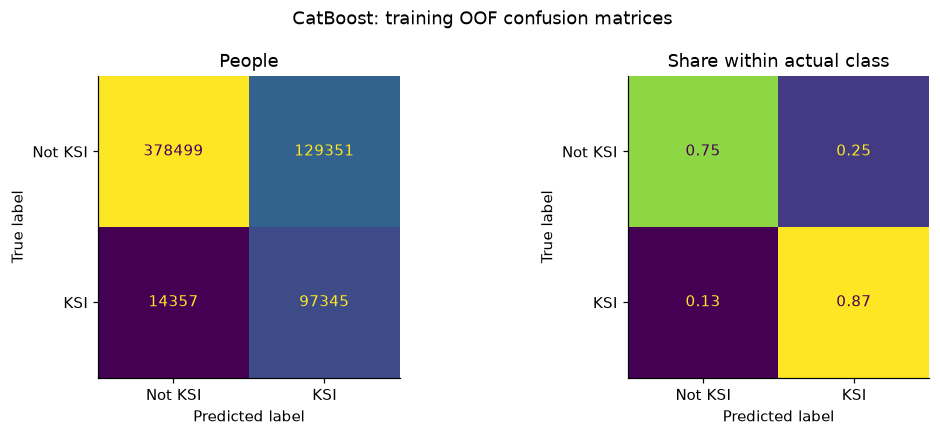

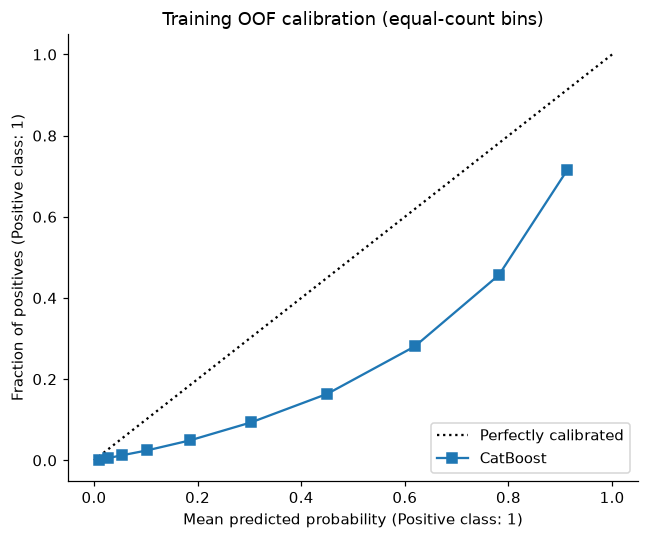

,group,value,n_people,n_ksi,tp,fn,fp,recall,precision,mean_prediction,observed_ksi
1,road_user,Bus / coach,7211,133,19,114,81,0.142857,0.190000,0.072362,0.018444
5,road_user,Heavy goods vehicle,14074,925,605,320,888,0.654054,0.405224,0.155386,0.065724
4,road_user,E-scooter / personal device,8907,1464,1048,416,2092,0.715847,0.333758,0.365679,0.164365
11,road_user,Van,38198,2881,2081,800,3585,0.722319,0.367279,0.170840,0.075423
6,road_user,Missing,865,84,62,22,78,0.738095,0.442857,0.152409,0.097110
24,vma,30.0,67193,6952,5244,1708,9652,0.754315,0.352041,0.235763,0.103463
16,vma,110.0,25922,3378,2625,753,4023,0.777087,0.394856,0.274818,0.130314
43,lum,5,95385,13250,10613,2637,18275,0.800981,0.367384,0.296850,0.138911
13,agg,2,382737,50248,41148,9100,64844,0.818898,0.388218,0.274224,0.131286
2,road_user,Car,358380,44711,36846,7865,56537,0.824093,0.394569,0.260387,0.124759


,road_user,agg,vma,missed_people,mean_score
40,Car,2,50.0,3177,0.202033
28,Car,1,80.0,1127,0.315465
107,Motorcycle >50cc,2,50.0,811,0.306425
136,Pedestrian,2,50.0,773,0.331738
29,Car,1,90.0,725,0.230343
91,Moped <50cc,2,50.0,665,0.308610
27,Car,1,70.0,590,0.269500
31,Car,1,110.0,543,0.240860
11,Bicycle,2,50.0,526,0.287620
32,Car,1,130.0,443,0.295162


At threshold 0.4237, we missed 14,357 of 111,702 KSI people. The Brier score is 0.1368. Among groups with at least 100 people and 30 KSI cases, the lowest recall is 14.3% for road_user=Bus / coach. The table shows where misses happen; it cannot tell us which missing measurement caused a miss. Actual impact speed, distraction and emergency response detail could help, but are not established explanations here.


In [4]:
from src.evaluation.m4_analysis import error_analysis, interpret_catboost
errors = error_analysis(meta, y, cat_oof, cat_row['threshold'], 'CatBoost', 'catboost')
display(errors['groups'].query('n_people >= 100 and n_ksi >= 30').sort_values('recall').head(15))
display(errors['false_negatives'].head(15))
print(errors['summary'])

## 4. What information does CatBoost use?

For permutation importance and SHAP, we use a model trained on outer fold 0 and a sample of complete accidents from its held-out fold. None of these people trained that model. Permutation importance asks how much average precision drops when a column is shuffled. We sample accidents together, then shuffle each feature across people; this is ordinary marginal permutation importance, not a causal intervention. Correlated features can share or hide importance, and shuffling can create unrealistic combinations.

SHAP breaks a prediction into feature contributions. We use CatBoost's native SHAP calculation and check that the contributions plus the expected value add up to the raw prediction. The bar plot uses mean absolute contributions in log-odds, so it shows magnitude, not whether each feature raises or lowers a particular person's score. [CatBoost SHAP documentation](https://catboost.ai/docs/en/concepts/shap-values)

The fold model was selected through training-data tuning, so these explanations are exploratory. They help us understand the model; they do not replace the final test.

/Users/colder/Documents/GitHub/road-accident-severity/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


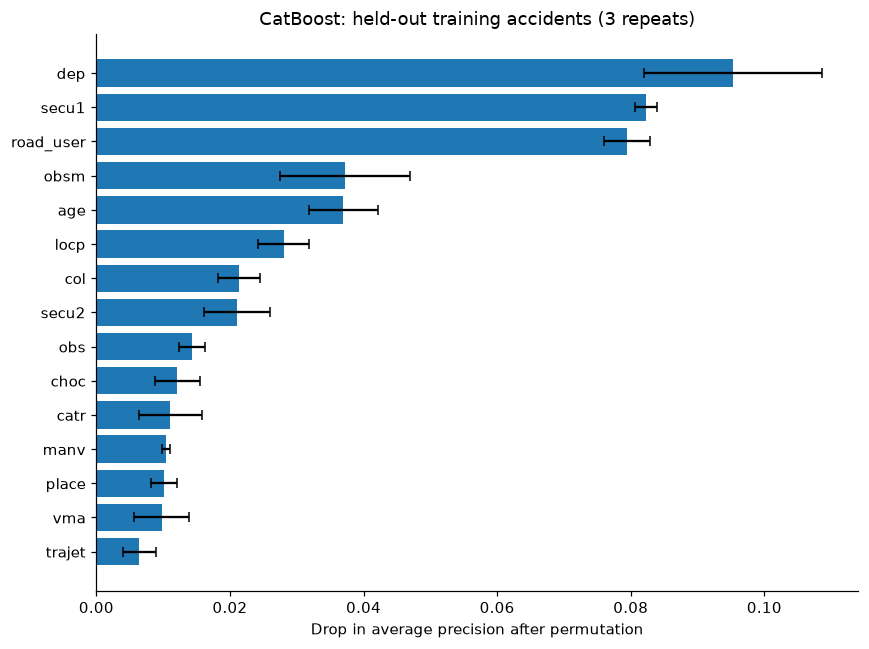

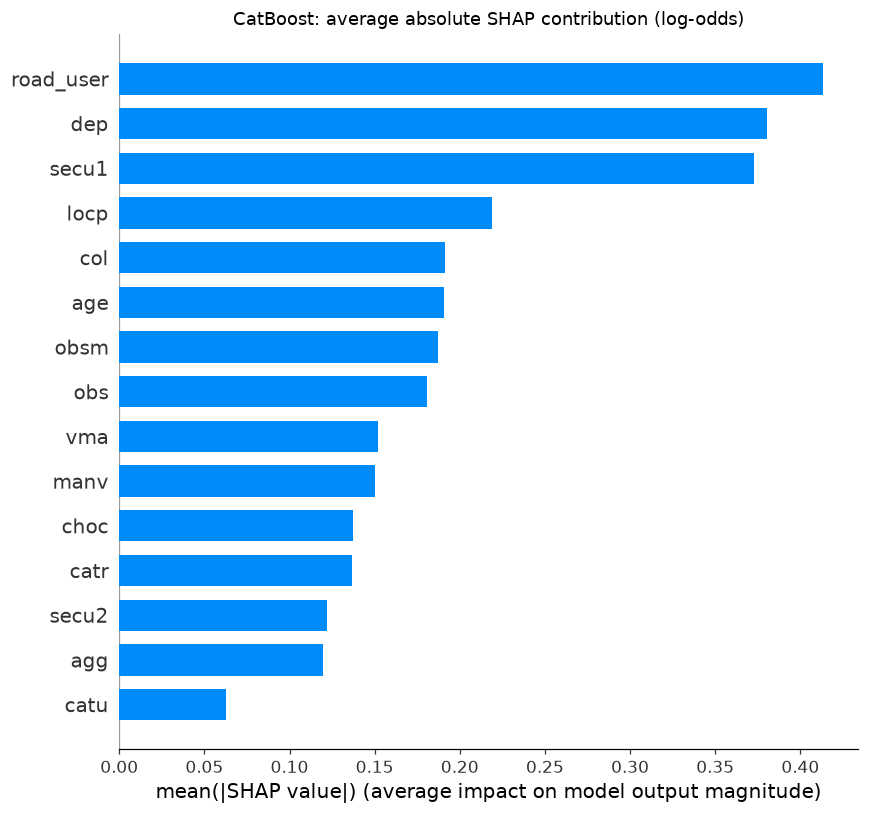

,feature,mean_ap_drop,std_ap_drop
13,dep,0.0953,0.0133
5,secu1,0.0823,0.0016
44,road_user,0.0794,0.0034
35,obsm,0.0372,0.0097
39,age,0.0370,0.0052
8,locp,0.0281,0.0038
18,col,0.0213,0.0031
6,secu2,0.0210,0.0049
34,obs,0.0143,0.0019
36,choc,0.0121,0.0034


,feature,mean_abs_shap
40,road_user,0.4132
21,dep,0.3801
13,secu1,0.3728
15,locp,0.2187
25,col,0.1913
0,age,0.1905
36,obsm,0.1871
35,obs,0.1808
8,vma,0.1520
38,manv,0.1501


,road_user,vma,obs,n_people,n_ksi,observed_ksi_rate,predicted_ksi_score,eligible_for_ranking
996,Motorcycle >50cc,80.0,2,244,205,0.8402,0.9629,True
993,Motorcycle >50cc,80.0,15,117,103,0.8803,0.9477,True
1000,Motorcycle >50cc,80.0,6,121,108,0.8926,0.9453,True
1002,Motorcycle >50cc,80.0,8,184,148,0.8043,0.9435,True
991,Motorcycle >50cc,80.0,13,917,705,0.7688,0.9417,True
997,Motorcycle >50cc,80.0,3,259,203,0.7838,0.9343,True
994,Motorcycle >50cc,80.0,16,212,150,0.7075,0.9328,True
969,Motorcycle >50cc,70.0,13,119,89,0.7479,0.9240,True
1009,Motorcycle >50cc,90.0,13,119,85,0.7143,0.9227,True
483,E-bike,80.0,0,167,122,0.7305,0.9221,True


Largest permutation drops: dep, secu1, road_user, obsm, age
Largest average SHAP contributions: road_user, dep, secu1, locp, col


In [5]:
heldout = joblib.load(CACHE / 'catboost_full_interpret.joblib')
valid = heldout['valid']
importance, shap_table, risks, risk_rates = interpret_catboost(
    heldout['model'], X.iloc[valid], y.iloc[valid], groups.iloc[valid], meta, y, cat_oof)
display(importance.head(15).round(4))
display(shap_table.head(15).round(4))
display(risks.query('eligible_for_ranking').head(20).round(4))
print('Largest permutation drops:', ', '.join(importance.head(5).feature))
print('Largest average SHAP contributions:', ', '.join(shap_table.head(5).feature))

## 5. Put the explanations next to the simpler evidence

We compare these rankings with the logistic odds ratios and the training EDA below. They answer different questions: logistic coefficients describe the fitted linear model, permutation importance describes a score drop, and SHAP describes a model contribution. Agreement can make a pattern easier to understand; disagreement can come from interactions, correlated inputs or a different model shape.

The situation table combines road user, speed limit and fixed-obstacle code. It shows counts, observed KSI rates and average OOF scores. We rank only groups with at least 100 people, but retain the smaller groups in the CSV. Average scores are not automatically calibrated KSI rates. This is a screening aid for further investigation, not an estimate of crash risk per kilometre.

We say **associated with**, not **causes**. Department patterns may partly reflect differences in recording hospital stays. The dataset also misses some behavioural and impact-speed information, so we cannot explain every false negative.

For numeric inputs, the logistic odds ratios are per standard deviation after scaling. The encoder keeps all category indicators, so a single category coefficient is not a clean comparison with an omitted reference category. A comparison between two categories uses their coefficient difference.

In [6]:
odds = pd.read_csv(RESULTS_DIR / 'logreg_odds_ratios.csv')
display(odds.head(15))
display(odds.tail(10))
display(risk_rates.query('n_people >= 100').sort_values('ksi_rate', ascending=False).head(25).round(4))
# Recompute a few EDA checks from the actual training rows rather than copying rounded claims.
checks = {
    'Tree obstacle (obs=2)': meta.obs.astype('string').eq('2').fillna(False),
    'Speed limit 80 km/h': meta.vma.eq(80),
    'No equipment recorded': X.equipment_none.eq(1),
}
eda_checks = pd.DataFrame([{'situation': name, 'n_people': int(mask.sum()),
    'observed_ksi_rate': float(y.loc[mask].mean())} for name, mask in checks.items()])
display(eda_checks.round(4))
eda_checks.to_csv(RESULTS_DIR / 'm4_eda_checks.csv', index=False)
print('The final test is still reserved for the next notebook.')

,feature,coef,odds_ratio
0,obsm_4,1.5643,4.7793
1,road_user_E-bike,1.1556,3.1758
2,road_user___MISSING__,0.9818,2.6693
3,road_user_Motorcycle >50cc,0.9483,2.5813
4,infra_7,0.9280,2.5295
5,road_user_Bicycle,0.9255,2.5231
6,road_user_E-scooter / personal device,0.9117,2.4886
7,road_user_Moped <50cc,0.7951,2.2147
8,dep_84,0.7639,2.1467
9,manv_6,0.7477,2.1121


,feature,coef,odds_ratio
384,dep_91,-0.8501,0.4274
385,sexe_None,-0.9398,0.3907
386,dep_93,-0.9818,0.3747
387,road_user_Van,-1.0579,0.3472
388,dep_94,-1.2948,0.2739
389,road_user_Heavy goods vehicle,-1.4396,0.2370
390,dep_92,-1.5142,0.2200
391,obsm_1,-1.6226,0.1974
392,dep_75,-1.7578,0.1724
393,road_user_Bus / coach,-2.6921,0.0677


,feature,value,n_people,ksi_rate
46,obs,17,776,0.6534
47,obs,2,11123,0.5627
42,obs,13,12754,0.4811
51,obs,6,8360,0.4392
39,obs,10,820,0.4061
45,obs,16,2904,0.3908
30,vma,80.0,87102,0.3886
44,obs,15,4083,0.3706
52,obs,7,2120,0.3693
7,road_user,Motorcycle >50cc,69870,0.3645


,situation,n_people,observed_ksi_rate
0,Tree obstacle (obs=2),11123,0.5627
1,Speed limit 80 km/h,87102,0.3886
2,No equipment recorded,52937,0.3917


The final test is still reserved for the next notebook.


## Reading our actual results

CatBoost reached **0.6469 OOF PR-AUC** on all training years. At the training-selected threshold of 0.4237, recall was 87.1% and precision was 42.9%. That means we should look at both the missed cases and the false alarms, rather than just the ranking score.

The largest held-out permutation drops came from **dep, secu1, road_user, obsm, age**. The largest average absolute SHAP contributions came from **road_user, dep, secu1, locp, col**. These lists summarize what this fitted model relies on. Their order need not match, because score drops and prediction contributions measure different things. We use the grouped error tables, EDA checks and logistic coefficients to put these rankings in context.

## What the patterns mean here

The calibration curve sits below the diagonal: the CatBoost scores tend to overstate the observed KSI frequency. Class weighting helps explain why a useful ranking is not automatically a calibrated probability. At our frozen threshold, bus/coach recall is only 14.3%, based on 133 KSI people out of 7,211 people in that group. The overall recall hides this weakness.

Road-user type and equipment records stand out in both the held-out importance results and the simpler evidence. The earlier logistic model also gives positive coefficients to motorcycle and e-bike categories. Those category coefficients depend on the full encoding, so we do not read them as standalone causal risk ratios. The training EDA gives 56.3% KSI for tree-obstacle records, 38.9% at an 80 km/h limit and 39.2% when no equipment is recorded. These are observed rates among recorded accident victims, while SHAP and permutation importance describe model behaviour.

The strong department effect deserves attention: it can mix real differences in circumstances with differences in recording hospital stays. The model cannot separate those explanations by itself.